In [43]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch
from matplotlib.patches import PathPatch
from matplotlib.path import Path

In [56]:
df = pd.read_csv('FreezingTimes.csv')
print(df)

    Group   Cup  Recall Control
0       1   0.0     0.0       y
1       2   0.0     0.0       y
2       3   0.0     0.0       y
3       4   1.8     0.0       y
4       5   0.0     4.7       y
5       6   5.2     0.0       y
6       7   0.0     0.0       y
7       8   0.0     0.0       y
8       9   0.0     2.1       y
9      10   3.7     4.7       y
10     11   0.0     0.0       y
11     12   0.0     5.1       y
12     13   4.8     7.2       y
13     14   0.0     2.5       y
14     15   0.0     0.0       y
15     16   1.2     0.0       y
16     17   0.0     2.9       y
17     18   0.0     0.0       y
18     19   0.0     0.0       y
19     20   0.0     0.0       y
20     21   0.0     0.0       y
21     22   3.7     0.0       y
22     23   0.0     1.7       y
23     24   0.0     0.0       y
24     25   2.6     0.0       y
25     26   0.0     0.0       y
26     27   1.2    25.4       n
27     28   0.0    29.8       n
28     29  15.6    59.5       n
29     30   5.1    58.3       n
30     3

In [57]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

In [58]:
def marker(filled=False):
    if (filled):
        return 'o'
    pts = np.linspace(0, np.pi * 2, 24)
    circ = np.c_[np.sin(pts) / 2, -np.cos(pts) / 2]
    vert = np.r_[circ, circ[::-1] * .7]
    return Path(vert)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


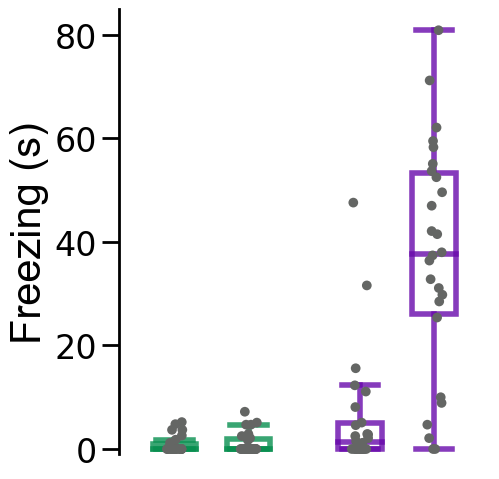

In [59]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["#646664","#646664"]
colors_boxplot = ['#078f4f',"#680aab"]
#colors_boxplot_filling = ['#aba9a9',"#aba9a9"]
colors_boxplot_filling = ['none',"none"]



ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    #order = ['n','y'],
    order = ['y','n'],
    y='Left preference',
    x='control',
    marker=marker(True),
    palette=colors,
    size=7,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    #order = ['n','y'],
    order = ['y','n'],
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

#plt.axhline(linewidth=2, color='lightgrey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

        

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')


ax.set_xlabel("",fontsize=20)

###

ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)

ax.set_ylim([-1,85])
#ax.set_yticks(np.arange(0,301,100), fontname='Arial')
#ax.set_yticklabels(['0','100','200','300'],fontname='Arial')

ax.set_xlim([-0.5,1.5])
ax.set_xticks([])

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Freezing (s)', fontsize = 30, fontname='Arial')

plt.legend([],[], frameon=False)



fig = ax.get_figure()
adjust_box_widths(fig, 0.6)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', labelsize=24)
ax.tick_params(axis='y', which='major', direction='out',length=12, labelsize=24, width=2)


plt.tight_layout()
fig.tight_layout()
fig.savefig("TimeFreezing.jpg",dpi=600,bbox_inches='tight')
plt.savefig('TimeFreezing.eps', format='eps', dpi=600)

